# EID — Feature Overview

A runnable tour of effective information (**EI**), integrated effective information (**Ξ**),
and the **Synergy Partition Tree (SPT)**. 

**Audience:** Python users familiar with NumPy arrays. **Prerequisites:** basic probability;
no external datasets, model weights, PySINDy, or scikit-learn are needed.
**Goal:** choose a response channel, run every supported workflow, and interpret both the
information values and their numerical diagnostics. Saved outputs make the tour readable on GitHub.

| Section | What you will learn | Example system |
|:--|:--|:--|
| [1. Basic usage](#1-basic-usage) | TPM analysis, source/target selection, bits and nats | COPY, XOR, noisy parity |
| [2. Time horizon](#2-time-horizon) | Form the full multi-step transition before marginalization | Two-node swap |
| [3. Discrete tools](#3-discrete-tools) | Rectangular channels, marginalization, coarse-graining | Boolean channels |
| [4. Continuous responses](#4-continuous-responses) | Shared interventions, noise, polynomial TM | Sum and product |
| [5. Nonlinear maps](#5-nonlinear-maps) | One-step and iterated response functions | Logistic and Hénon maps |
| [6. ODE responses](#6-ode-responses) | Explicit integration and a declared forecast interval | Damped oscillator, Lorenz |
| [7. Learned models](#7-learned-models) | Fit, hold out, validate, then intervene on a model | Linear response predictor |
| [8. Hierarchies](#8-hierarchies) | Exact, spectral, random, and constrained SPT searches | Boolean gates, ring dynamics, coupled oscillators |
| [9. Density models](#9-density-models) | Affine, quadratic, and polynomial transport maps | Gaussian and banana densities |
| [10. MI tools](#10-mi-tools) | Weighted, pointwise, specific, and pairwise information | Noisy continuous channels |
| [11. Diagnostics and export](#11-diagnostics-and-export) | Tolerance audits, explicit failure, JSON, compatibility | Deliberate numerical examples |
| [12. Coverage and practice](#12-coverage-and-practice) | Locate every public workflow and modify a small example | Noise sensitivity |

The three original scripts, `discrete_xor.py`, `known_dynamics.py`, and `learned_model.py`,
are reproduced as notebook workflows in Sections 1, 4, and 7. Supporting systems and checks live in [helpers.py](helpers.py) and [spt_examples.py](spt_examples.py); figure and table formatting
lives in [plotting.py](plotting.py). Each code cell has at most 10 lines and shows only
parameters, core EID calls, or result displays.

## Setup

From the repository root, install the optional notebook dependencies and open this file:

```bash
python -m pip install -e '.[notebooks]'
python -m jupyter lab examples/1_feature_overview/example.ipynb
```

Select that environment's Python kernel, then **Restart Kernel and Run All Cells**.
Run from either the repository root or this notebook's directory. Figures are embedded as PNGs; the three SPT galleries are also saved in the local `fig/` folder.
No data files or caches are written. The default run uses small examples rather than a parameter search.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/eid").is_dir())
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "examples/1_feature_overview")]
import helpers as demo
import plotting as plots


In [2]:
import numpy as np
from eid import (
    UniformBox, analyze_tpm, analyze_dynamics, analyze_model,
    build_deterministic_boolean_tpm, SPTConfig, build_spt, build_spt_from_ei_table,
)
%matplotlib inline
demo.show_environment()


EID 0.1.1 | NumPy 2.4.6 | SciPy 1.17.1 | Matplotlib 3.11.2


The shared settings below control reproducibility and numerical tolerances.


In [3]:
SEED = 7                  # Intervention and measurement-noise seed.
SAMPLE_COUNT = 4096        # Independent intervention samples per analysis.
DISCRETE_TOL = 1e-12       # Exact-channel roundoff allowance, in bits.
CONTINUOUS_TOL = 0.03      # Syn error allowance, in nats; never an automatic fix.

FIG_DIR = ROOT / "examples/1_feature_overview/fig"

### What the numbers mean

All terms in a decomposition share **one full intervention ensemble, one fixed target,
one forecast interval, and one estimation protocol**:

\[
\mathrm{EI}(A\to B)=I(\mathbf{x}_A;\mathbf{y}_B),\qquad
\Xi(A\to B)=\mathrm{EI}(A\to B)-\sum_{i\in A}\mathrm{EI}(\{i\}\to B).
\]

For two sources, Ξ is two-source **Syn**. With more sources, it is **integrated EI**;
SPT node Syn values are contributions along the chosen tree, not unique pure-order PID atoms.
A nonlinear response need not have more synergy than an additive response.

Discrete examples use **bits**; continuous examples use **nats** unless marked otherwise.
`bits × ln(2) = nats`. Values from different supports, noise channels, targets, or horizons
answer different questions and should not be ranked as system-intrinsic scores.

| Parameter | Simple English explanation |
|:--|:--|
| `n_nodes` | Number of binary variables; a full TPM has shape `(2**n_nodes, 2**n_nodes)`. |
| `sources` | Current input coordinates to analyze; omitted inputs are marginalized, not fixed. |
| `targets` | Response coordinates used jointly as the fixed target. |
| `horizon` | Number of full TPM transition steps; only `analyze_tpm` applies it automatically. |
| `bounds` / `UniformBox` | One `[lower, upper]` interval per full input coordinate, sampled independently. |
| `response_noise_std` | Positive standard deviation of the added Gaussian measurement channel; scalar or one per output. |
| `sample_count` | Number of intervention samples; more samples do not cure a mismatched density family. |
| `seed` | Random seed for a reproducible ensemble. |
| `degree` | Maximum degree of polynomial conditional regressions in the TM. |
| `joint_order` | Coordinate order in the joint density; the continuous adapter defaults to `source_first`. |
| `unit` | `"nats"` or `"bits"`; the low-level TM MI helpers always return bits. |
| `syn_tolerance` | Allowed numerical error in the declared unit; raw estimates are retained and audited. |
| `exact_max_size` | Largest source coalition searched exhaustively; larger coalitions use spectral candidates. |

**Estimation boundary.** Continuous public analyses fit and score polynomial triangular TMs
on the same ensemble, with Gaussian conditional residuals and no finite-sample bias correction.
These are estimates, not exact nonlinear-channel information. This tour uses one fixed seed
and shows no uncertainty intervals. Numerical Syn below `-syn_tolerance` must fail; changing
sample count, support, or model family requires reassessment, not automatic tolerance inflation.

**Manuscript check, 2026-10-08.** Zotero parent `P6UJCVG8` was verified as
*Emergent hierarchical organization of causal interactions in complex systems*.
The currently available main attachment `DXGC7JEA` and supplement `MWIWKSVG` were re-read:
Methods Eqs. (5)–(12), pp. 15–17; S1.1–S1.2, Eqs. (S1)–(S15); S5.1–S5.2,
Eqs. (S49)–(S51). Neither attachment declares a manuscript version/date, so “latest draft”
is unresolved. S1.2's affine TM + fixed feature lift + bias correction differs from the
current polynomial public adapter. The density demonstrations below do not implement that
paper estimator. See [the method contract](../../docs/method_contract.md) for remaining boundaries.

<a id="1-basic-usage"></a>
## 1. Basic usage

Construct a full deterministic Boolean TPM, then choose the future target. States are
lexicographically ordered: `00, 01, 10, 11`. Here the second future coordinate is retained
only to make a square full-system TPM; the analyzed target is the first coordinate.

In [4]:
copy_tpm = build_deterministic_boolean_tpm(2, lambda s: (s[0], s[1]))
xor_tpm = build_deterministic_boolean_tpm(2, lambda s: (s[0] ^ s[1], s[1]))
xor = analyze_tpm(
    xor_tpm, n_nodes=2, sources=[0, 1], targets=[0], horizon=1,
    unit="bits", syn_tolerance=DISCRETE_TOL,
)
copy_result = analyze_tpm(copy_tpm, n_nodes=2, targets=[0], unit="bits", syn_tolerance=DISCRETE_TOL)
plots.show_results({"COPY": copy_result, "XOR": xor})


System,Joint EI,Σ single EI,Ξ,Unit,Syn tol.,Min. candidate Syn,Tol. Syn count,Tol. Ξ count,Closure
COPY,1.0000,1.0000,0.0000,bits,1e-12,0,0,0,0.0e+00
XOR,1.0000,0.0000,1.0000,bits,1e-12,1,0,0,0.0e+00


### Probabilistic updates and nonconsecutive source indices

`build_probabilistic_boolean_tpm` forms a full TPM from independent Bernoulli node updates.
`adjacency[i, j]` points from current node `i` to future node `j`; coefficients act inside
a logistic activation. The first output below is a noisy parity channel on sources 0 and 2.
Source 1 is still independently intervened and then marginalized.

System,Joint EI,Σ single EI,Ξ,Unit,Syn tol.,Min. candidate Syn,Tol. Syn count,Tol. Ξ count,Closure
COPY,1.0000,1.0000,0.0000,bits,1e-12,0,0,0,0.0e+00
XOR,1.0000,0.0000,1.0000,bits,1e-12,1,0,0,0.0e+00
Noisy parity,0.3791,0.0000,0.3791,bits,1e-12,0.3791,0,0,0.0e+00


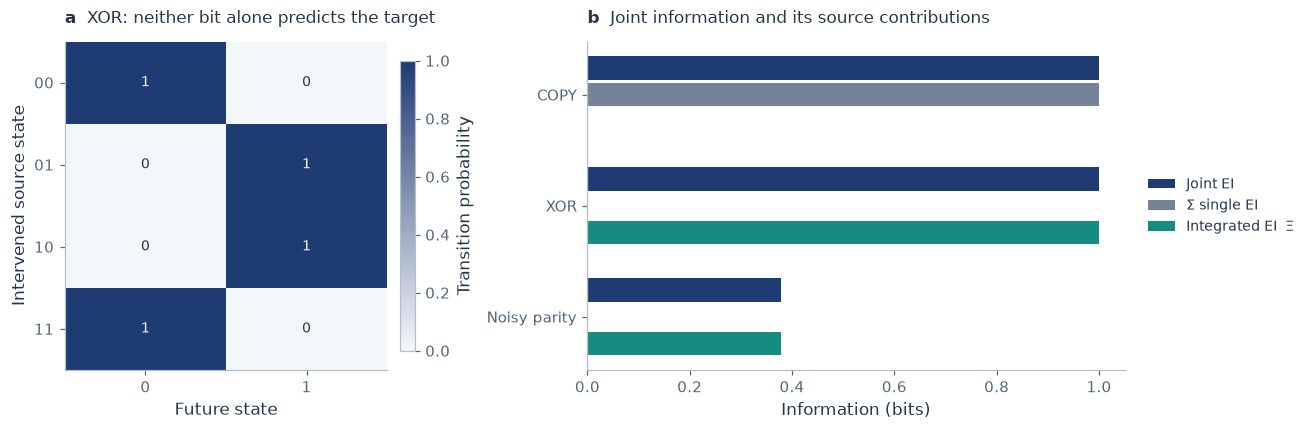

In [5]:
noisy_tpm = demo.noisy_parity_tpm(strength=1.7)
noisy_parity = analyze_tpm(
    noisy_tpm, n_nodes=3, sources=[0, 2], targets=[0],
    unit="bits", syn_tolerance=DISCRETE_TOL,
)
boolean_results = {"COPY": copy_result, "XOR": xor, "Noisy parity": noisy_parity}
plots.show_results(boolean_results)
plots.show_boolean(xor_tpm, boolean_results)


COPY has one bit of single-source EI and zero Ξ. XOR has zero single-source EI but one bit
of Ξ. Stochastic parity loses information through its noise channel. All three use exact
discrete calculations rather than a fitted estimator.

In [6]:
xor_nats = analyze_tpm(
    xor_tpm, n_nodes=2, targets=[0], unit="nats", syn_tolerance=DISCRETE_TOL * np.log(2),
)
plots.show_table(["Quantity", "bits", "nats"], [["XOR Ξ", xor.xi, f"{xor_nats.xi:.6f}"]])


Quantity,bits,nats
XOR Ξ,1.0,0.693147


<a id="2-time-horizon"></a>
## 2. Time horizon

The swap system alternates which current coordinate reaches future coordinate 0.
`analyze_tpm` computes the full kernel `tpm**horizon` **before** source/target marginalization.
Iterating an already marginalized one-step channel would discard the hidden coordinate's memory.

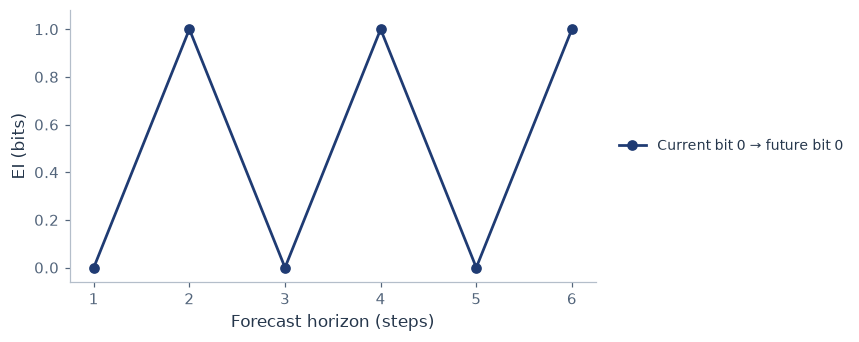

Horizon,EI (bits),Ξ (bits)
1,0.0,0.0
2,1.0,0.0
3,0.0,0.0
4,1.0,0.0
5,0.0,0.0
6,1.0,0.0


In [7]:
swap_tpm = build_deterministic_boolean_tpm(2, lambda s: (s[1], s[0]))
horizons = np.arange(1, 7)
lag_results = {
    int(lag): analyze_tpm(
        swap_tpm, n_nodes=2, sources=[0], targets=[0], horizon=int(lag),
        unit="bits", syn_tolerance=DISCRETE_TOL,
    )
    for lag in horizons
}
plots.show_horizons(horizons, lag_results)


<a id="3-discrete-tools"></a>
## 3. Discrete tools

Low-level functions let you inspect the actual channels. Marginalization retains the
common full-state intervention. Coarse-graining instead defines macro input/output states;
`effective_information_from_tpm` then intervenes uniformly over the **macro rows**.
This is a different protocol when macro states have unequal numbers of microstates.
The generic EI function also accepts rectangular, non-binary channels; it does not build an SPT.

Channel,Shape,EI (bits),Input intervention
Full COPY,"(4, 4)",2.0,Uniform over 4 microstates
Single source → XOR,"(2, 2)",0.0,Marginal of full intervention
OR macro COPY,"(2, 2)",1.0,Uniform over 2 macro states
Three-state channel,"(3, 2)",0.6667,Uniform over 3 inputs


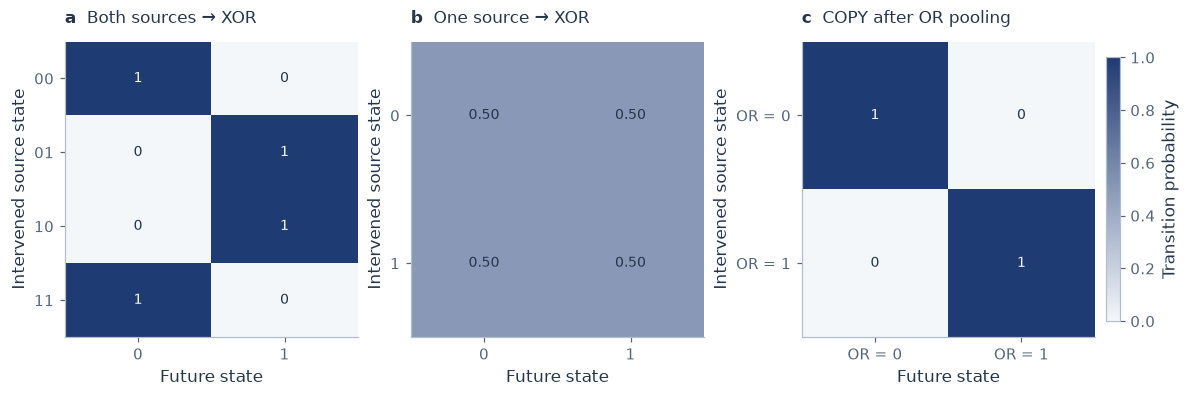

In [8]:
from eid.discrete import source_subset_tpm, target_subset_tpm, source_target_tpm, coarse_grain_binary_or_tpm
source_only = source_subset_tpm(xor_tpm, 2, [0])
target_only = target_subset_tpm(xor_tpm, 2, [0])
rectangular = source_target_tpm(xor_tpm, 2, source_indices=[0], target_indices=[0])
macro_or = coarse_grain_binary_or_tpm(copy_tpm, n_nodes=2, groups=[[0, 1]])
three_state_channel = np.array([[1.0, 0.0], [0.5, 0.5], [0.0, 1.0]])
demo.check_discrete_channels(copy_tpm, xor_tpm, source_only, target_only, rectangular, macro_or)
plots.show_discrete_channels(copy_tpm, target_only, rectangular, macro_or, three_state_channel)


<a id="4-continuous-responses"></a>
## 4. Continuous responses

Pass a batch response function: input shape `(sample_count, input_dimension)`;
output shape `(sample_count,)` or `(sample_count, output_dimension)`.
The adapter draws one complete `UniformBox` ensemble, evaluates the response once,
adds the declared measurement noise once, and reuses the samples for all EI subsets.

Our channels have dimensionless state coordinates and synthetic independent Gaussian
measurement noise with known standard deviation **0.3**. Noise is part of this example's
measurement model, not a numerical floor added to make deterministic information finite.

In [9]:
box = UniformBox([[-1, 1], [-1, 1]])
sum_response, product_response = demo.sum_response, demo.product_response
continuous_kwargs = dict(
    intervention=box, response_noise_std=0.3, syn_tolerance=CONTINUOUS_TOL,
    sample_count=SAMPLE_COUNT, seed=SEED, joint_order="source_first", unit="nats",
)
sum_result = analyze_dynamics(sum_response, degree=1, **continuous_kwargs)
product_result = analyze_dynamics(product_response, degree=2, **continuous_kwargs)
plots.show_results({"Additive response": sum_result, "Product response": product_result})


System,Joint EI,Σ single EI,Ξ,Unit,Syn tol.,Min. candidate Syn,Tol. Syn count,Tol. Ξ count,Closure
Additive response,1.0414,0.5661,0.4753,nats,0.03,0.4753,0,0,0.0e+00
Product response,0.3947,0.0007,0.3940,nats,0.03,0.394,0,0,0.0e+00


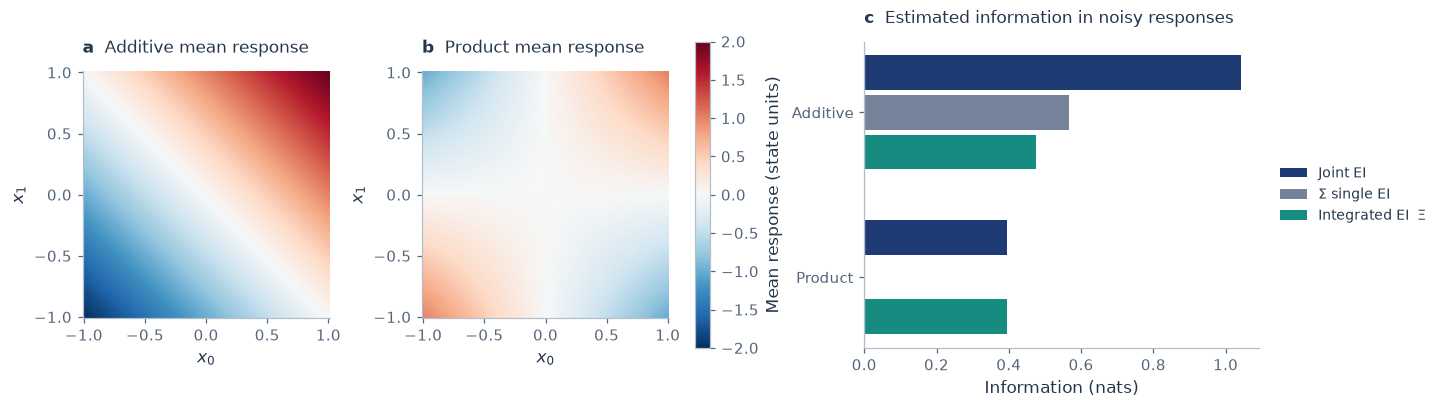

In [10]:
plots.show_continuous(sum_response, product_response, sum_result, product_result)


The product channel mainly carries joint information. The additive channel can also have
positive Ξ: observing a noisy sum does not reveal either independently intervened input alone.
The colored surfaces show the **noise-free channel mean**; EI includes the stated noise.

<a id="5-nonlinear-maps"></a>
## 5. Nonlinear maps

A continuous adapter does not iterate a map automatically. Encode the requested number of
steps inside the response. The logistic map illustrates a one-source analysis (Ξ = 0);
the two-coordinate Hénon map illustrates vector outputs and per-output measurement noise.
These are new illustrative examples, not reproductions of the manuscript's benchmark protocols.

In [11]:
logistic_rate, logistic_steps, logistic_noise = 3.7, 1, 0.08
logistic_response = demo.logistic_map(rate=logistic_rate, steps=logistic_steps)
logistic_result = analyze_dynamics(
    logistic_response, intervention=UniformBox([[0, 1]]), response_noise_std=logistic_noise,
    syn_tolerance=CONTINUOUS_TOL, sample_count=SAMPLE_COUNT, degree=2, seed=SEED, unit="nats",
)
logistic_result.metadata.update(map_steps=logistic_steps, logistic_rate=logistic_rate)


The Hénon example uses two outputs and a separate noise scale for each.


In [12]:
henon_a, henon_b, henon_noise = 1.4, 0.3, [0.10, 0.06]
henon_response = demo.henon_map(a=henon_a, b=henon_b)
henon_box = UniformBox([[-1, 1], [-0.4, 0.4]])
henon_result = analyze_dynamics(
    henon_response, intervention=henon_box, response_noise_std=henon_noise,
    syn_tolerance=CONTINUOUS_TOL, sample_count=SAMPLE_COUNT, degree=2, seed=SEED, unit="nats",
)
henon_result.metadata.update(map_steps=1, henon_a=henon_a, henon_b=henon_b)
plots.show_results({"Logistic, one-step": logistic_result, "Hénon, joint outputs": henon_result})


System,Joint EI,Σ single EI,Ξ,Unit,Syn tol.,Min. candidate Syn,Tol. Syn count,Tol. Ξ count,Closure
"Logistic, one-step",1.2876,1.2876,0.0000,nats,0.03,n/a,0,0,0.0e+00
"Hénon, joint outputs",2.7127,1.9254,0.7873,nats,0.03,0.7873,0,0,0.0e+00


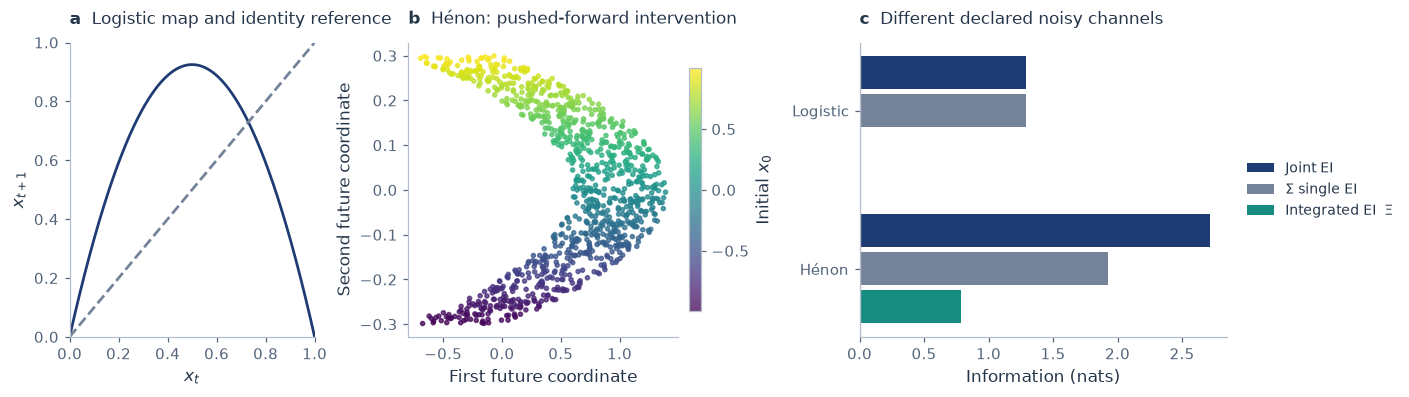

In [13]:
plots.show_maps(logistic_response, henon_response, henon_box, logistic_result, henon_result, seed=SEED)


The Hénon point cloud is a one-step pushforward of **independent uniform interventions**,
not an attractor trajectory. The identity reference shows logistic fixed-point intersections.
To study several steps, change the response loop and its polynomial approximation;
long chaotic forecasts may require a density family beyond the current TM.

<a id="6-ode-responses"></a>
## 6. ODE responses

Integrate the ODE inside your response, then analyze the **future state**, not the derivative.
State coordinates and time use dimensionless benchmark units here. Measurement noise is added
only after integration, so these are noisy observation channels of deterministic flows.

In [14]:
frequency, damping_ratio, oscillator_horizon = 1.5, 0.15, 0.8
oscillator_response = demo.oscillator_flow(frequency, damping_ratio, horizon=oscillator_horizon)
oscillator_result = analyze_dynamics(
    oscillator_response, intervention=box, targets=[0], response_noise_std=[0.12, 0.12],
    syn_tolerance=CONTINUOUS_TOL, sample_count=SAMPLE_COUNT, degree=1, seed=SEED, unit="nats",
)
oscillator_result.metadata.update(forecast_interval=oscillator_horizon, integrator="matrix-exponential")


Lorenz uses a fixed RK4 step; the forecast interval is `dt × steps`.


In [15]:
lorenz_dt, lorenz_steps = 0.01, 8
lorenz_response = demo.lorenz_flow(dt=lorenz_dt, steps=lorenz_steps)
lorenz_box = UniformBox([[-8, 8], [-8, 8], [20, 30]])
lorenz_result = analyze_dynamics(
    lorenz_response, intervention=lorenz_box, targets=[1], response_noise_std=[0.5, 0.5, 0.5],
    syn_tolerance=CONTINUOUS_TOL, sample_count=SAMPLE_COUNT, degree=3, seed=SEED, unit="nats",
)
lorenz_result.metadata.update(forecast_interval=lorenz_dt*lorenz_steps, integrator="RK4", integration_step=lorenz_dt)


Check integration separately from the information estimator, then compare the channels.


In [16]:
integration_difference = demo.check_lorenz_integration(lorenz_response, lorenz_box, lorenz_dt, lorenz_steps)
plots.show_results({"Oscillator → position": oscillator_result, "Lorenz → y": lorenz_result})


Lorenz RK4 step-halving maximum state difference: 3.74e-05


System,Joint EI,Σ single EI,Ξ,Unit,Syn tol.,Min. candidate Syn,Tol. Syn count,Tol. Ξ count,Closure
Oscillator → position,1.2323,0.6118,0.6205,nats,0.03,0.6205,0,0,0.0e+00
Lorenz → y,2.3092,1.2162,1.0930,nats,0.03,0.5119,0,0,0.0e+00


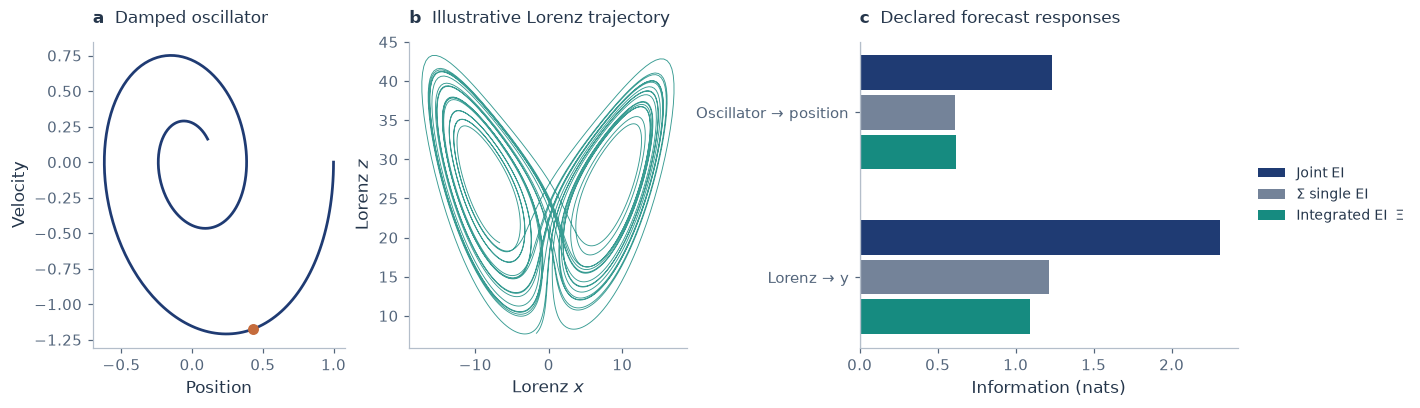

In [17]:
plots.show_odes(oscillator_response, demo.lorenz_vector_field, oscillator_result, lorenz_result)


The phase portraits explain the mechanisms; the orange oscillator dot marks the forecast
endpoint. The information bars use separately drawn uniform interventions. The two-source oscillator has Syn = Ξ; Lorenz has three sources,
so its root value is Ξ and its internal SPT contributions depend on the selected partition path.

<a id="7-learned-models"></a>
## 7. Learned models

Any fitted object with a batch `predict(X)` method can be analyzed. This reproduces
`examples/learned_model.py`: generate a noisy linear response, fit with NumPy, estimate
measurement error on untouched holdout samples, and analyze the fitted model over its
training support. These samples are independent interventions; a real time series would
need a time-ordered split, explicit history variables, and a defined forecast lag.

Holdout samples,RMSE,Residual SD,"Coefficients: intercept, x0, x1"
750,0.2911,0.2913,[-0.002 1.0178 1.0152]


System,Joint EI,Σ single EI,Ξ,Unit,Syn tol.,Min. candidate Syn,Tol. Syn count,Tol. Ξ count,Closure
Fitted linear model,1.0820,0.5746,0.5074,nats,0.03,0.5074,0,0,0.0e+00


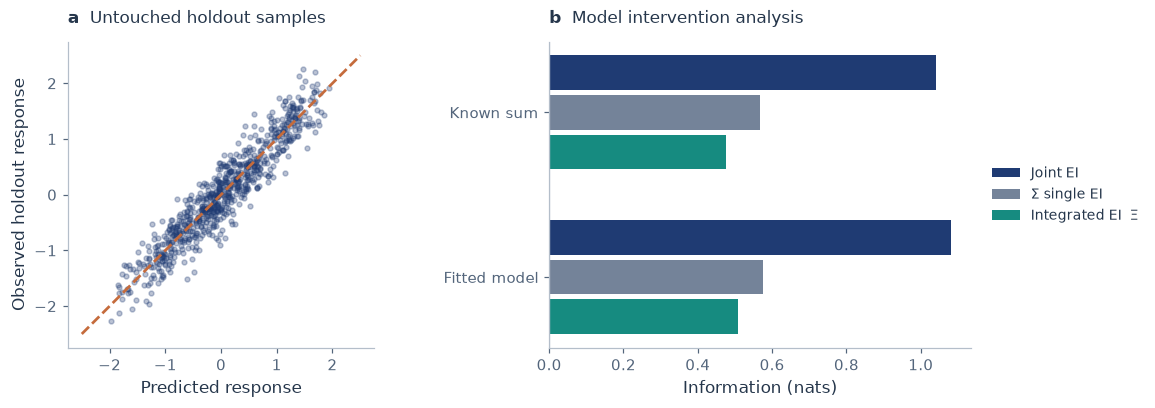

In [18]:
training = demo.fit_linear_example(seed=13, sample_count=3000, train_count=2250, noise_std=0.3)
model = training.model
learned_kwargs = dict(continuous_kwargs, response_noise_std=training.noise_std, degree=1)
learned_result = analyze_model(model, **learned_kwargs)
model_as_dynamics = analyze_dynamics(model.predict, **learned_kwargs)
demo.check_model_adapter(learned_result, model_as_dynamics, training)
plots.show_model(training, learned_result, sum_result)


The two bars use different declared noise scales: 0.3 for the known channel and the measured
holdout residual SD for the model. The information describes interventions on the fitted
predictor. Good prediction by itself does not establish causal identification of a real system.

<a id="8-hierarchies"></a>
## 8. Hierarchies

Two independent XOR modules share a fixed joint future target `(output 0, output 2)`.
An exact SPT should retain each module's one-bit Ξ in its own child and assign zero
cross-module Syn to the root. At each node the standard objective maximizes the two
children's retained Ξ; recursion continues to singleton sources.

**Node percentages.** Each internal label is $100\times\mathrm{Syn}(A)/\Xi(V)$,
using that tree's total integrated EI as the denominator. The internal contributions sum to
100% before rounding; leaf Syn is zero. Root Syn can be smaller than 100% because children
retain part of the total. Original Ξ/Syn values and units remain in the tables and result objects.
If total Ξ is at or below the declared native-unit tolerance, percentage labels are `n/a`.
Tolerance-scale negative estimates stay signed and receive a †; they are numerical diagnostics,
not evidence for negative Syn. Values below the tolerance still fail explicitly.

In [19]:
from eid.spt import TableXiOracle, pairwise_syn_affinity
pair_tpm = demo.xor_modules_tpm(pair_count=2)
pair_result = analyze_tpm(
    pair_tpm, n_nodes=4, targets=[0, 2], unit="bits", syn_tolerance=DISCRETE_TOL, exact_max_size=8,
)
pair_table = pair_result.ei_table
config = SPTConfig(syn_tolerance=DISCRETE_TOL)
table_tree = build_spt_from_ei_table(pair_result.sources, pair_table, config=config)


The same complete EI table can serve as an oracle and supply pairwise Syn affinities.


System,Joint EI,Σ single EI,Ξ,Unit,Syn tol.,Min. candidate Syn,Tol. Syn count,Tol. Ξ count,Closure
Two XOR modules,2.0000,0.0000,2.0000,bits,1e-12,0,0,0,0.0e+00


SPT contribution,Order,Syn (bits)
"(0, 1)",2,1.0
"(2, 3)",2,1.0


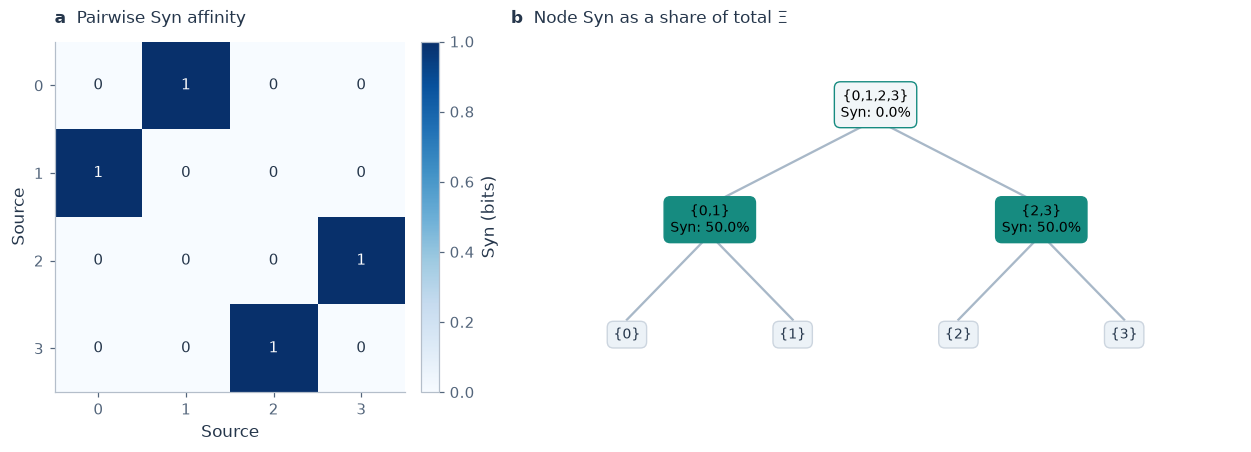

In [20]:
oracle = TableXiOracle(pair_table, pair_result.sources)
oracle_tree = build_spt(pair_result.sources, oracle, config=config)
affinity, affinity_tolerance_count = pairwise_syn_affinity(oracle, 4, tolerance=DISCRETE_TOL)
plots.show_hierarchy(pair_result, table_tree, affinity)


### Exact versus candidate searches

For larger source sets, the public adapter switches to spectral candidates above
`exact_max_size`. Exact search is optimal **at each node**, not across all complete trees;
spectral and random searches optimize only the candidates they evaluate.

The random selector and local refinement are lower-level options. `initial_budget` counts
initial splits per large node; `candidate_budget` caps that node's evaluated splits including
local refinement. `local_search_top_k` chooses how many initial candidates to refine.

In [21]:
three_pair_tpm = demo.xor_modules_tpm(pair_count=3)
search_kwargs = dict(n_nodes=6, targets=[0, 2, 4], unit="bits", syn_tolerance=DISCRETE_TOL)
exact_six = analyze_tpm(three_pair_tpm, exact_max_size=8, **search_kwargs)
spectral_six = analyze_tpm(three_pair_tpm, exact_max_size=2, **search_kwargs)
six_oracle = TableXiOracle(exact_six.ei_table, exact_six.sources)
six_affinity, six_affinity_count = pairwise_syn_affinity(six_oracle, 6, tolerance=DISCRETE_TOL)


At the lower level, supply a spectral selector or a random selector with local refinement.


In [22]:
from eid.spt import spectral_candidate_selector, stratified_random_candidate_selector
manual_spectral = build_spt(
    exact_six.sources, six_oracle, config=config,
    candidate_selector=spectral_candidate_selector(six_affinity, exact_max_size=2),
)
random_tree = build_spt_from_ei_table(
    exact_six.sources, exact_six.ei_table,
    config=SPTConfig(syn_tolerance=DISCRETE_TOL, candidate_budget=15, local_search_top_k=2),
    candidate_selector=stratified_random_candidate_selector(initial_budget=7, exact_max_size=2, seed=SEED),
)


In [23]:
plots.show_searches(exact_six, spectral_six, manual_spectral, random_tree)
demo.check_hierarchies(pair_result, table_tree, oracle_tree, affinity_tolerance_count, six_affinity_count)


Search,Evaluated splits,EI queries,EI table complete?,Closure (bits)
Exact at each node,41,63,True,0.0
Public spectral,27,46,False,0.0
Manual spectral,27,Reused table,Supplied complete table,0.0
Random + local refinement,25,Reused table,Supplied complete table,0.0


### Domain-constrained candidates

A custom candidate selector changes legal partitions while retaining the same EI table
and objective. This intentionally imposed cross-module split moves both bits of contribution
to the root. Its closure is unchanged, illustrating why higher-order tree contributions
are **path dependent**. A zero node contribution does not stop the standard tree.

Partition path,Root split,Root Syn (bits),Sum of node Syn (bits),Closure
Standard exact,"[(0, 1), (2, 3)]",0.0,2.0,0.0
Imposed prior,"[(0, 2), (1, 3)]",2.0,2.0,0.0


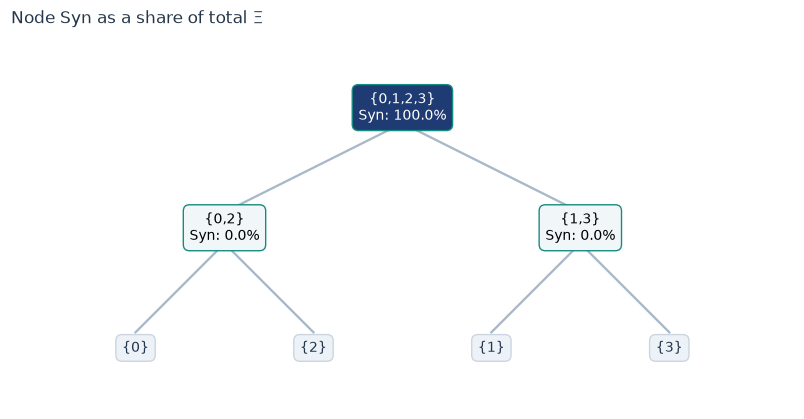

In [24]:
allowed_splits = {
    (0, 1, 2, 3): ((0, 2), (1, 3)),
    (0, 2): ((0,), (2,)),
    (1, 3): ((1,), (3,)),
}
prior_tree = build_spt_from_ei_table(
    pair_result.sources, pair_table, config=config,
    candidate_selector=demo.fixed_split_selector(allowed_splits),
)
plots.show_prior(table_tree, prior_tree, syn_tolerance=DISCRETE_TOL)


### Six different interaction structures

The following cases were declared for variety, without a parameter search. They use exact
uniform interventions over all binary inputs and a fixed one-step response in each model.
Source identifiers in the trees are the input coordinate indices.

| Model | Analyzed response |
|:--|:--|
| Pair + triad | Two separate parity outputs from `{0,1}` and `{2,3,4}` |
| Global parity | XOR of all six inputs |
| Gated parity | AND of the three pairwise XOR outputs |
| Overlapping parity | Two parity outputs sharing source 2 |
| Majority vote | One when at least three of five inputs are one |
| Switched logic | Source 0 selects either `x1 XOR x2` or source 3 |

Each tree uses the same standard SPT objective and continues to singletons. Differences
between models include the response and target dimension; this is a gallery of mechanisms,
not a ranking of system-intrinsic synergy. All raw information and diagnostics remain below.

In [25]:
import spt_examples as spt_demo
structure_cases = spt_demo.structure_cases()
structure_results = {
    name: analyze_tpm(
        case.tpm, n_nodes=case.n_nodes, targets=case.targets, horizon=case.horizon,
        unit="bits", syn_tolerance=DISCRETE_TOL,
    )
    for name, case in structure_cases.items()
}

System,Joint EI,Σ single EI,Ξ,Unit,Syn tol.,Min. candidate Syn,Tol. Syn count,Tol. Ξ count,Closure
Pair + triad,2.0000,0.0000,2.0000,bits,1e-12,0,0,0,0.0e+00
Global parity,1.0000,0.0000,1.0000,bits,1e-12,0,0,0,0.0e+00
Gated parity,0.5436,0.0000,0.5436,bits,1e-12,0.01771,0,0,0.0e+00
Overlapping parity,2.0000,0.0000,2.0000,bits,1e-12,0,0,0,0.0e+00
Majority vote,1.0000,0.5198,0.4802,bits,1e-12,0.02029,0,0,0.0e+00
Switched logic,1.0000,0.1887,0.8113,bits,1e-12,0.1887,0,0,0.0e+00


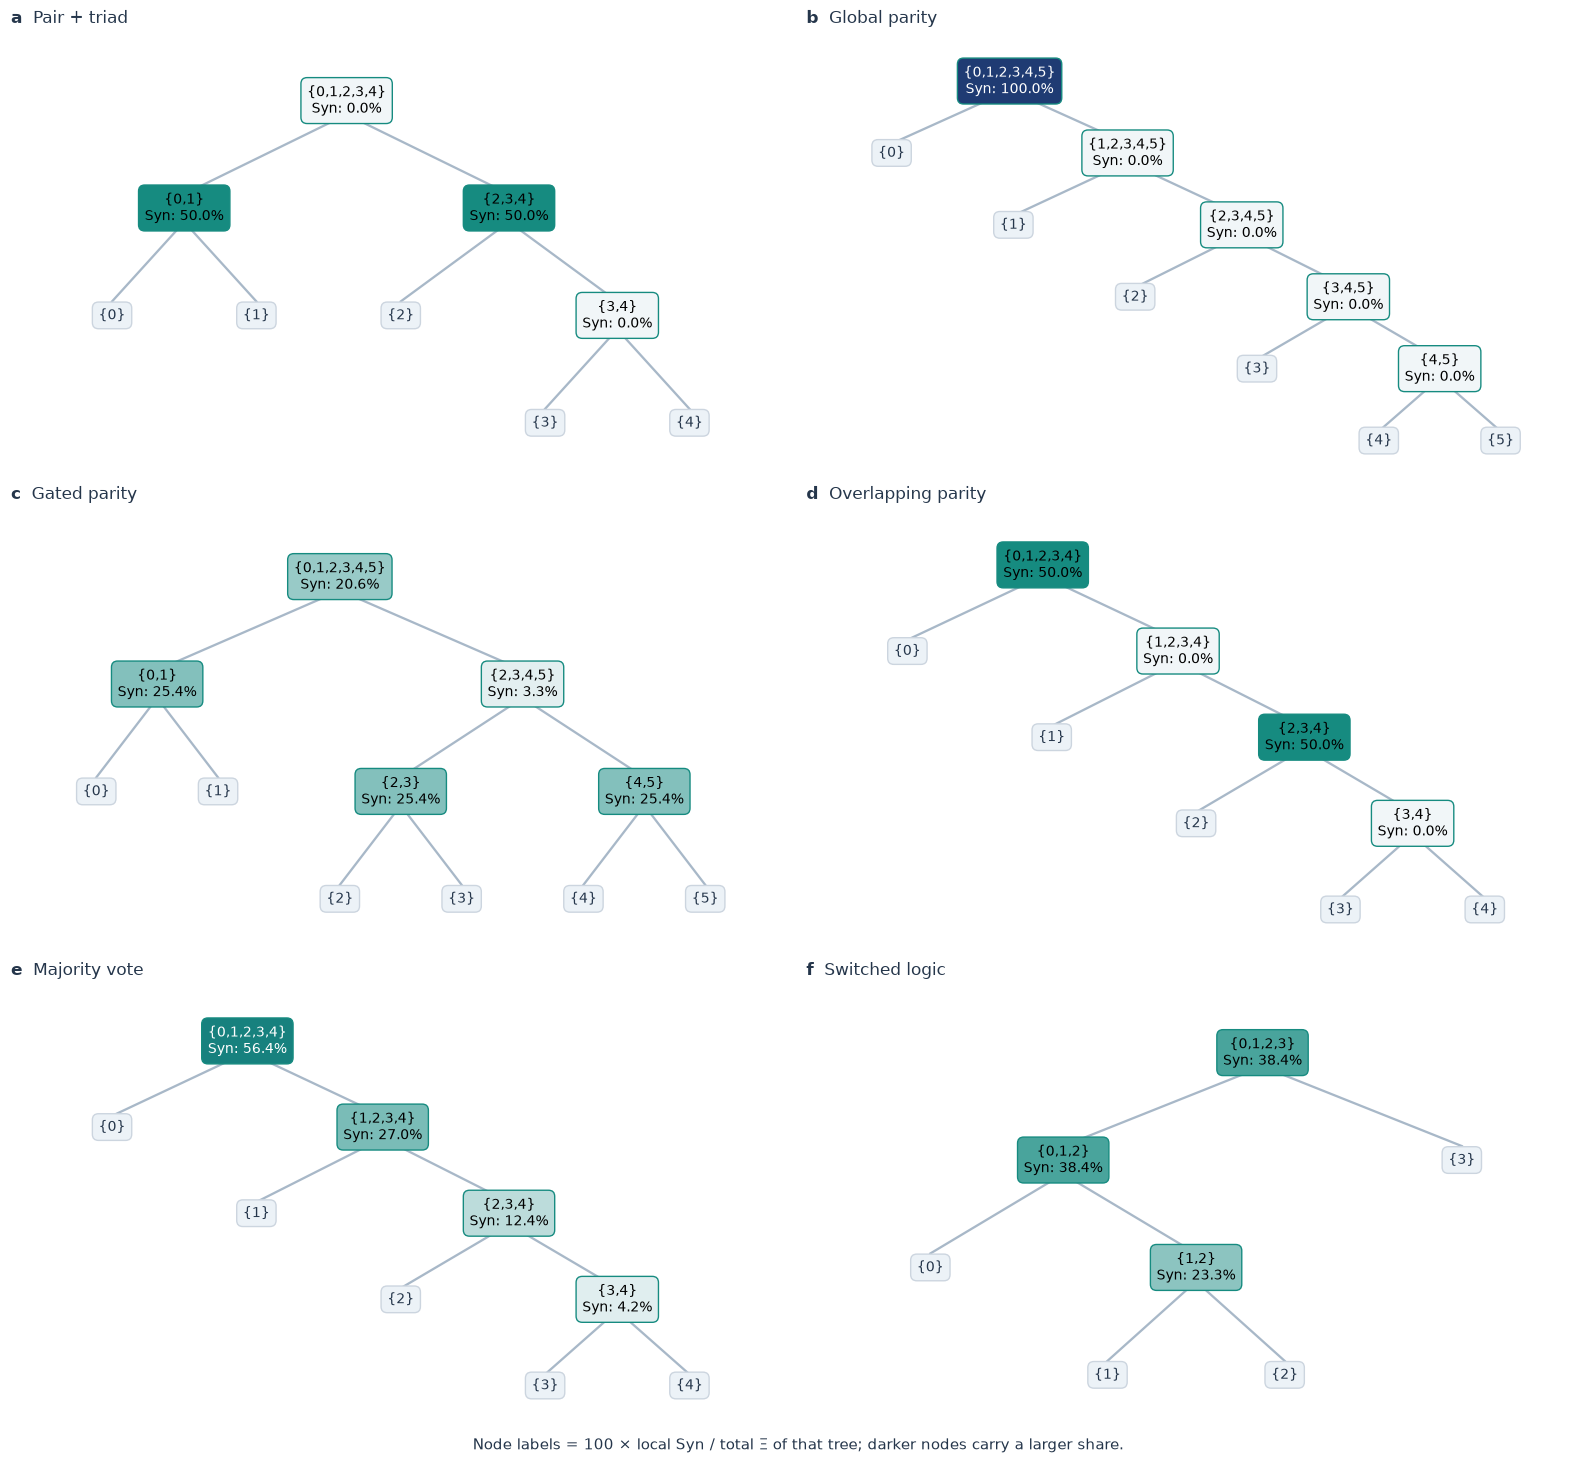

In [26]:
spt_demo.annotate_discrete_results(structure_results, structure_cases)
plots.show_spt_gallery(structure_results, columns=2, path=FIG_DIR / "spt_structures.png")

Separate pair/triad modules retain **50% each**, whereas global parity retains **100% at the
root**. Gated parity spreads mass over the root and three pair nodes; majority vote decreases
through successive levels. Switched and overlapping logic allocate mass along different paths.

Zero-mass nodes stay visible. Tied candidates, especially in global parity and symmetric
majority vote, are resolved deterministically: their displayed paths do not identify a unique
causal wiring diagram. Percentages show local tree contributions, not pure-order PID atoms.

### A Boolean dynamical network at three horizons

For six sites on a periodic ring, update all sites simultaneously by
`x_i' = x_(i-1) XOR (x_i AND x_(i+1))`. Change only the forecast horizon to **1, 2, or 3**;
the full independent-uniform intervention, target site 0, and exact estimator stay fixed.
The complete transition kernel is iterated before any source/target marginalization.

In [27]:
relay_cases = spt_demo.relay_cases(horizons=[1, 2, 3])
relay_results = {
    name: analyze_tpm(
        case.tpm, n_nodes=case.n_nodes, targets=case.targets, horizon=case.horizon,
        unit="bits", syn_tolerance=DISCRETE_TOL,
    )
    for name, case in relay_cases.items()
}

System,Joint EI,Σ single EI,Ξ,Unit,Syn tol.,Min. candidate Syn,Tol. Syn count,Tol. Ξ count,Closure
Boolean relay · h=1,1.0000,0.1887,0.8113,bits,1e-12,0,0,0,0.0e+00
Boolean relay · h=2,1.0000,0.1887,0.8113,bits,1e-12,0,0,0,0.0e+00
Boolean relay · h=3,0.9972,0.0833,0.9139,bits,1e-12,0.09255,0,0,0.0e+00


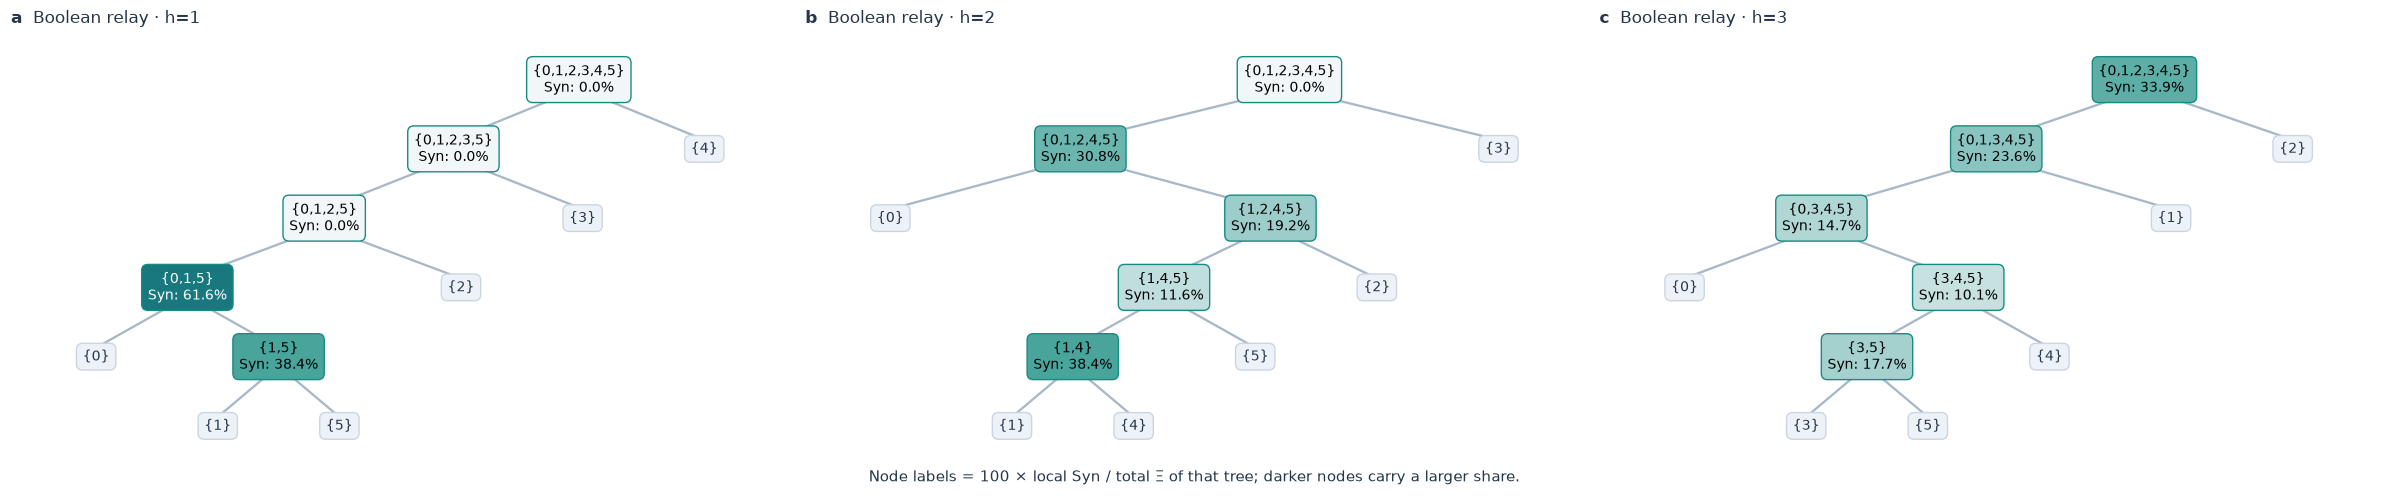

In [28]:
spt_demo.annotate_discrete_results(relay_results, relay_cases)
plots.show_spt_gallery(relay_results, columns=3, path=FIG_DIR / "spt_boolean_horizons.png")

At one step, the nonzero contributions involve sites `{0,1,5}`. At later horizons, information
reaches more sites and moves across levels. At horizon 3 the six-source root carries about
**33.9%** of total Ξ. These are exact channel results for this finite ring, with no sampling
uncertainty; the zero-mass branches are completed by the standard singleton stopping rule.

### Coupled continuous dynamics

Three damped oscillators use state `[q0,q1,q2,v0,v1,v2]` and the dimensionless ODE
$\dot{\mathbf{q}}=\mathbf{v}$, $\dot{\mathbf{v}}=-\mathbf{K}\mathbf{q}-\mathbf{D}\mathbf{v}$.
The fixed stiffness and damping matrices are declared in [spt_examples.py](spt_examples.py).
An exact matrix exponential produces the future state; the target is **future q1**.

Only the forecast interval changes between **0.4 and 1.2**. Both analyses reuse identical
uniform `[-1,1]^6` input samples and Gaussian observation-noise draws (SD **0.2**), with
4096 samples, seed 7, degree-1 TM, and **0.03-nat** Syn tolerance. The existing Lorenz tree
is included for a different nonlinear mechanism, with its separately declared channel.

In [29]:
forecast_times = [0.4, 1.2]
coupled_kwargs = dict(
    intervention=UniformBox([[-1, 1]] * 6), targets=[1], response_noise_std=0.2,
    sample_count=SAMPLE_COUNT, seed=SEED, degree=1, unit="nats", syn_tolerance=CONTINUOUS_TOL,
)

In [30]:
coupled_responses = {f"Coupled oscillators · t={t:.1f}": spt_demo.coupled_oscillator_flow(t) for t in forecast_times}
coupled_results = {
    name: analyze_dynamics(response, **coupled_kwargs)
    for name, response in coupled_responses.items()
}
spt_demo.annotate_flow_results(coupled_results, coupled_responses)

System,Joint EI,Σ single EI,Ξ,Unit,Syn tol.,Min. candidate Syn,Tol. Syn count,Tol. Ξ count,Closure
Coupled oscillators · t=0.4,1.0325,0.7434,0.2891,nats,0.03,4.488e-05,0,15,0.0e+00
Coupled oscillators · t=1.2,0.7801,0.4970,0.2831,nats,0.03,0.0311,0,1,0.0e+00
Lorenz → future y,2.3092,1.2162,1.0930,nats,0.03,0.5119,0,0,0.0e+00


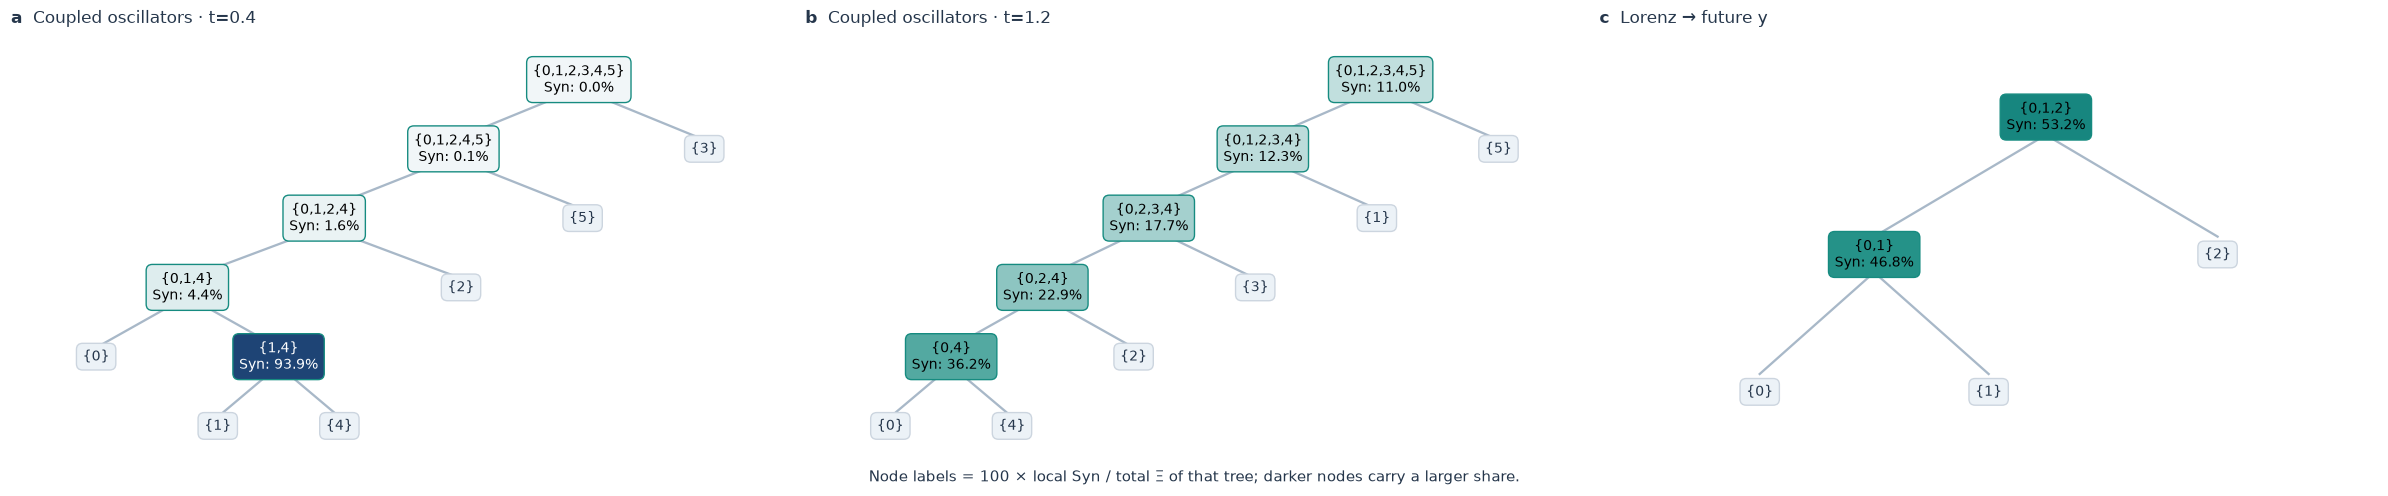

In [31]:
dynamics_trees = dict(coupled_results, **{"Lorenz → future y": lorenz_result})
plots.show_spt_gallery(dynamics_trees, columns=3, path=FIG_DIR / "spt_continuous_dynamics.png")

At interval 0.4, about **93.9%** of the oscillator Ξ sits at `{q1,v1}`. At interval 1.2,
the largest pair becomes `{q0,v1}` with about **36.2%**, while larger groups retain more mass.
The displayed one-decimal percentages are rounded; unrounded raw values remain in the results.

The integration is exact for this linear flow; the uniform-input TM information is still an
approximation, with no uncertainty intervals or bias correction. Neither the oscillator
example nor the Boolean ring reproduces the manuscript's benchmark protocols. Lorenz's
support, noise, target and estimator differ, so its absolute information is not ranked against
the oscillator values. All cases retain the nonnegativity audit and greedy SPT closure check.

The two oscillator runs retain 15 and 1 tolerance-scale negative queried Ξ values, respectively
(minima −4.96×10⁻⁵ and −6.36×10⁻⁶ nats); these are numerical estimator diagnostics.
Their selected node Syn values are nonnegative, all candidate Syn checks pass, and no
negative values are clipped or reinterpreted as physical negative synergy.

<a id="9-density-models"></a>
## 9. Density models

These are density utilities, separate from a PEID analysis. A fitted transport map
maps observations to a standard Gaussian reference and evaluates the corresponding density.
The affine family fits a Gaussian; quadratic and general polynomial families model
nonlinear conditional means with Gaussian residuals.

`jitter` regularizes the **affine covariance**. `ridge` regularizes **polynomial regression**;
`min_scale` is a numerical residual-scale floor. None is a physical response-noise parameter.
The historical `jitter` argument to polynomial MI does not affect its current implementation.

In [32]:
from eid.estimators.transport_map import (
    fit_affine_transport_map_density, fit_quadratic_triangular_transport_map_density,
    fit_polynomial_triangular_transport_map_density,
)
density_data = demo.density_samples(bend=0.6, seed=41)
affine_gaussian = fit_affine_transport_map_density(density_data.gaussian_train, jitter=1e-6)


Fit the same banana training sample with three density families.


In [33]:
banana_models = {
    "Affine": fit_affine_transport_map_density(density_data.banana_train),
    "Quadratic": fit_quadratic_triangular_transport_map_density(density_data.banana_train, min_scale=1e-8),
    "Polynomial, degree 2": fit_polynomial_triangular_transport_map_density(
        density_data.banana_train, degree=2, ridge=1e-6, min_scale=1e-8,
    ),
}
gaussian_log_rmse, density_errors = demo.evaluate_densities(density_data, affine_gaussian, banana_models)


Held-out density model,Log-density RMSE (natural log units)
Affine on Gaussian,0.0129
Affine on banana,1.4279
Quadratic on banana,0.0417
"Polynomial, degree 2 on banana",0.0417


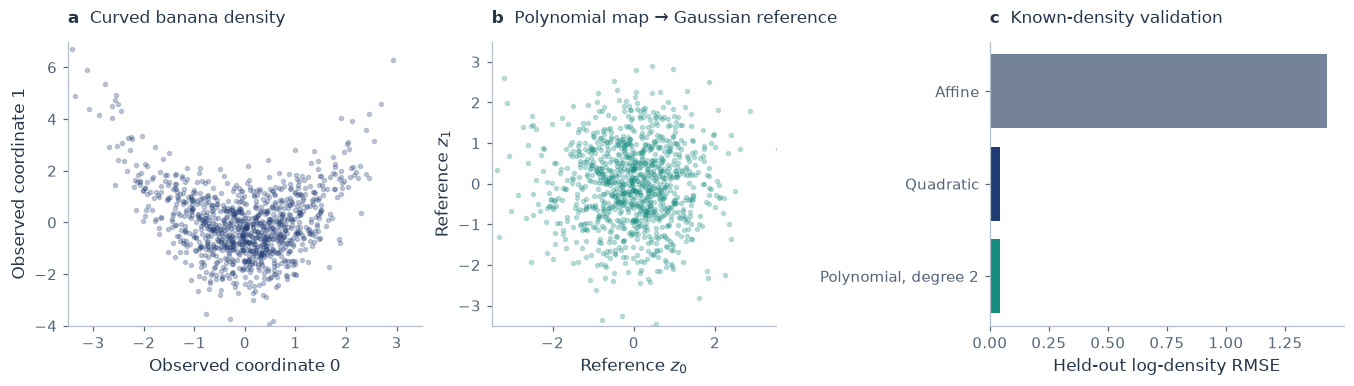

In [34]:
plots.show_densities(density_data, banana_models, gaussian_log_rmse, density_errors)


### Marginal densities and conditional sampling

`AffineTransportMapDensityEstimator.marginal` returns a Gaussian marginal.
`PolynomialTriangularTransportMapDensityEstimator.sample_conditional` fixes a **prefix**
of coordinates and samples the remainder in the fitted coordinate order.

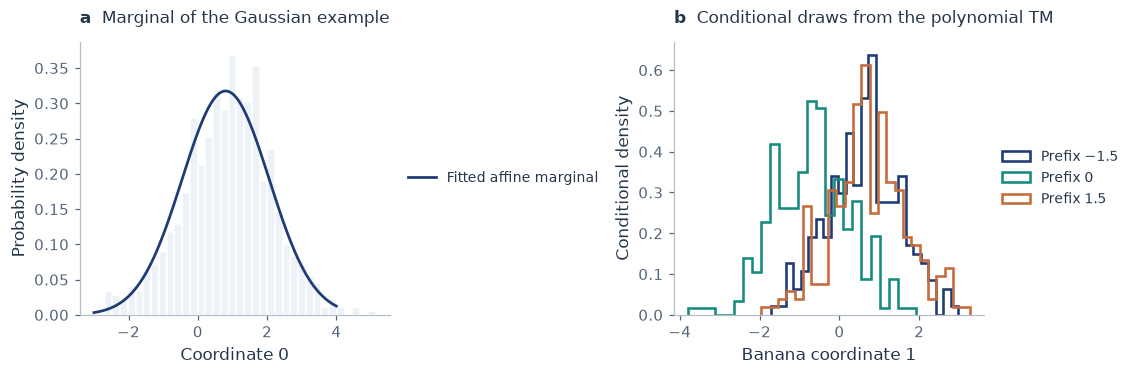

In [35]:
gaussian_marginal = affine_gaussian.marginal([0])
prefixes = np.array([[-1.5], [0.0], [1.5]])
conditional_draws = banana_models["Polynomial, degree 2"].sample_conditional(
    prefixes, samples_per_prefix=250, seed=SEED,
)
plots.show_conditionals(density_data.gaussian_test, gaussian_marginal, conditional_draws, prefixes)


<a id="10-mi-tools"></a>
## 10. MI tools

The low-level TM helpers take paired samples and return **bits**. Their MI is EI only when
the samples actually represent the declared intervention and response mechanism.
Weights change the sampled distribution; arbitrary observational or reweighted samples
must not be presented as the independent-uniform intervention used by the public adapter.

The Gaussian channel below supplies a simple analytic MI reference. `pointwise_mi` is a
per-observation log density ratio; individual values may be negative. `specific_mi` instead
averages conditional draws at fixed target anchors. Neither is a PEID Syn atom.

In [36]:
from eid.estimators.transport_map import (
    estimate_mutual_information_transport_map, estimate_specific_mutual_information_transport_map,
    pairwise_effective_information_for_dynamics,
)
correlation = 0.75
mi_x, mi_y = demo.gaussian_channel(correlation=correlation)
mi = estimate_mutual_information_transport_map(mi_x, mi_y, degree=1, joint_order="source_first")
analytic_mi_bits = -0.5 * np.log2(1 - correlation**2)


Weights define a different sampled distribution. Uniform weights reproduce the unweighted estimate.


In [37]:
mi_uniform_weight = estimate_mutual_information_transport_map(
    mi_x, mi_y, degree=1, joint_order="source_first", sample_weight=np.ones(len(mi_x)),
)
weights = np.where(mi_x[:, 0] > 0, 2.0, 1.0)
weighted_mi = estimate_mutual_information_transport_map(
    mi_x, mi_y, degree=1, joint_order="source_first", sample_weight=weights,
)
weighted_density = fit_polynomial_triangular_transport_map_density(
    np.column_stack([mi_x, mi_y]), degree=1, sample_weight=weights,
)


Query specific MI on a target grid, then inspect the global and per-observation estimates.


Distribution,MI estimate (bits),Effective sample size
Gaussian analytic reference,0.5963,n/a
Unweighted sample,0.5693,3000
Uniform weights,0.5693,3000
Nonuniform reweighting,0.5463,2696


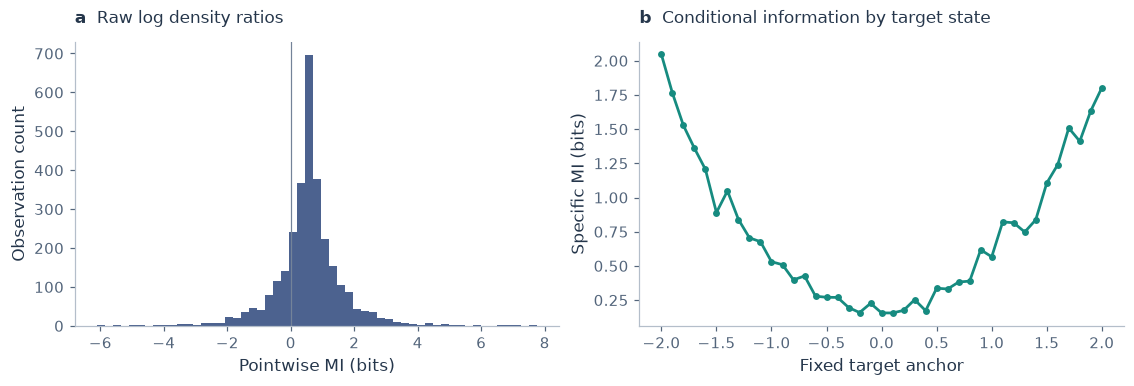

In [38]:
anchor_values = np.linspace(-2.0, 2.0, 41)[:, None]
specific = estimate_specific_mutual_information_transport_map(
    mi_x, mi_y, target_anchors=anchor_values, degree=1, conditional_samples=256, seed=SEED,
)
demo.check_mi(mi, mi_uniform_weight, analytic_mi_bits)
plots.show_mi(mi, mi_uniform_weight, weighted_mi, analytic_mi_bits, anchor_values, specific)


The uniformly spaced specific-MI anchors are a query grid, not draws from the target
marginal. Consequently, `specific["mi_hat"]` is the mean over this grid and is **not** the
Gaussian channel's global MI. Marginally sampled target anchors would be needed for that average.

### Pairwise input → output information

This legacy convenience helper samples a box described by `center` and full `box_size`,
then uses degree-3, **target-first** polynomial MI. It has no measurement-noise argument:
noise must be implemented in the response itself. No clipping is enabled. Pairwise EI
is not pairwise Syn; the full-input response is evaluated once and shared by all pairs.

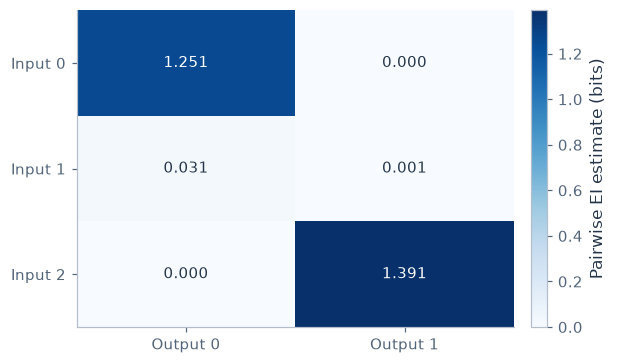

Input,Output 0 EI (bits),Output 1 EI (bits)
0,1.2507,0.0002
1,0.0307,0.0008
2,0.0002,1.3911


In [39]:
pairwise_noisy_response = demo.noisy_pairwise_response(noise_std=0.25, seed=23)
pairwise = pairwise_effective_information_for_dynamics(
    pairwise_noisy_response, input_indices=[0, 1, 2], output_indices=[0, 1], input_dim=3,
    center=[0, 0, 0], box_size=[2, 2, 2], sample_count=SAMPLE_COUNT, seed=SEED, clip_negative=False,
)
plots.show_pairwise(pairwise)


<a id="11-diagnostics-and-export"></a>
## 11. Diagnostics and export

`result.ei_table` contains **queried subsets**, not necessarily every subset. Check
`ei_table_complete` before reusing it for a different candidate search. `metadata` retains
the intervention, noise, seed, estimator, and horizon conventions; `diagnostics` retains
native-unit tolerances and affected counts. Information values are unnormalized.

In [40]:
exported = demo.export_result(lorenz_result)
plots.show_export(exported)


Result field,Example value
unit,nats
sources → targets,"[0, 1, 2] → [1]"
estimator,polynomial_triangular_transport_map_degree_3
response noise SD,"[0.5, 0.5, 0.5]"
forecast interval / integrator,0.08 / RK4
density fit/evaluation,same-intervention-ensemble
EI table complete,True
minimum queried Ξ,0.008430
SPT closure,0.0


### Tolerance-scale negatives are retained; larger violations fail

The following deliberately inconsistent EI tables are numerical audit examples, not physical
negative-synergy channels. The first residual is within a declared **0.01-bit** tolerance;
its raw value stays negative and its affected count is recorded. The second must raise
`SPTNonnegativityError` with a minimum, threshold, and count. No clipping or signed workaround
is used to report a PEID result.

In [41]:
audit_tolerance_bits = 0.01
audit = demo.tolerance_audit(audit_tolerance_bits)
plots.show_tolerance_audit(audit)


Unit,Tolerance,Raw Syn,Affected count,Closure
bits,0.01,-0.005,1,0.0


Expected explicit failure: Syn nonnegativity violation in split ('a',) | ('b',): minimum=-0.1, threshold=-0.01, affected_count=1.


### Historical compatibility and nonstandard settings

`eid.compat` maps the old Phi names onto the canonical SPT. New code should use `eid.spt`.
The historical `xi_bits`/`syn_bits` aliases are not unit declarations: read `xi_value`,
`syn_value`, and the enclosing analysis unit.

The next cell calls a helper demonstrating retained legacy settings: `SIGNED` is a diagnostic
policy; `ALL_ORDER_CROSS_DENSITY` changes the split objective; `complete_to_singletons=False`
with `eps` enables a historical terminal shortcut. These are not the standard PEID/SPT protocol.

In [42]:
legacy = demo.legacy_examples(pair_result, DISCRETE_TOL, audit_tolerance_bits, audit.bad_table)
plots.show_legacy(legacy)


Legacy option,Observed behavior,Interpretation
Phi compatibility,Total atoms = 2.0 bits,Same canonical tree
SIGNED,Raw residual = -0.100 bits,Invalid Syn retained for diagnostics only
Cross-coalition normalization,Closure = 0.0e+00 bits,"Different objective, not standard SPT"
Early terminal,terminal,Not the standard singleton stopping rule


<a id="12-coverage-and-practice"></a>
## 12. Coverage and practice

| Public surface | Demonstrated in |
|:--|:--|
| `analyze_tpm`, `build_deterministic_boolean_tpm` | 1, 2, 8 |
| `analyze_dynamics`, `UniformBox.dimension/sample` | 4, 5, 6 |
| `analyze_model`, `AnalysisResult`, `to_dict` | 7, 11 |
| `build_spt`, `build_spt_from_ei_table`, `SPTConfig`, `SPTNonnegativityError` | 8, 11 |
| `effective_information_from_tpm` (square and rectangular) | 3 |
| Probabilistic Boolean builder, binary-state enumeration | 1, 3 |
| Source/target TPM helpers and exact subset EI | 1, 3 |
| Output aggregation, state-label and OR coarse-graining | 3 |
| Table Ξ oracle, subset enumeration, node/atom flattening | 8 |
| Exact, spectral, stratified-random, and custom split selectors | 8 |
| Candidate inspection, pairwise Syn affinity, closure | 8 |
| Affine, quadratic, polynomial TM classes and fitting | 9 |
| `pdf`, `log_prob`, `map_to_reference`, affine `marginal`, polynomial `sample_conditional` | 9 |
| Gaussian log-density helpers, polynomial density weights | 9, 10 |
| TM MI, `sample_weight`, pointwise MI, specific MI | 10 |
| Pairwise dynamics EI with declared simulator noise | 10 |
| Syn auditing, compatibility wrappers, legacy policies/objectives/stopping | 11 |

All names exported by the top-level `eid.__all__` are exercised by the cells and their helpers. Private implementation
helpers are not a user-facing API. General time-series training, neural conditional TMs,
group/Shapley attribution, and the manuscript's full domain experiments are not currently
implemented by this toolbox.

### Practice: change the observation channel

**Exercise.** Keep the product response, support, seed, and estimator fixed. Compare
measurement SD 0.15, 0.30, and 0.60. Predict how the information changes before running
the answer scaffold below. Check the reported minima/counts before interpreting the results;
a fixed-seed estimated ordering is not a statistical uncertainty statement.

System,Joint EI,Σ single EI,Ξ,Unit,Syn tol.,Min. candidate Syn,Tol. Syn count,Tol. Ξ count,Closure
Noise SD 0.15,0.8843,0.0005,0.8838,nats,0.03,0.8838,0,0,0.0e+00
Noise SD 0.30,0.3947,0.0007,0.3940,nats,0.03,0.394,0,0,0.0e+00
Noise SD 0.60,0.1291,0.0009,0.1282,nats,0.03,0.1282,0,0,0.0e+00


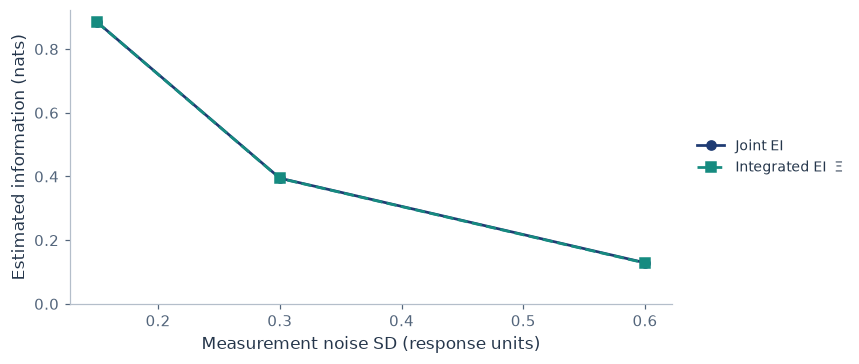

In [43]:
noise_levels = [0.15, 0.30, 0.60]
noise_results = {
    f"Noise SD {noise:.2f}": analyze_dynamics(
        product_response, **dict(continuous_kwargs, response_noise_std=noise, degree=2),
    )
    for noise in noise_levels
}
plots.show_results(noise_results)
plots.show_noise(noise_levels, noise_results)


In this fixed example, both estimated joint EI and Ξ decline as noise increases. The plotted
raw values and numerical diagnostics support that local observation. Increasing observation
noise cannot increase exact MI for a fixed input channel, but an estimated Ξ trend is not a
general monotonicity theorem.

**Common pitfalls.** Do not compute different subsets under separately selected interventions;
do not pass a derivative when you intend a future state; do not infer units from old `*_bits`
field names; do not use pointwise MI or observational MI as Syn; do not hide invalid estimates
with clipping or a larger tolerance.

**Optional extension.** Modify the oscillator forecast interval while holding the input box,
measurement noise, and TM family fixed. Keep the complete response and its interval explicit.
For larger examples inspect `ei_table_complete` and the search diagnostics before reusing tables.

In [44]:
all_standard_results = [
    *boolean_results.values(), xor_nats, *lag_results.values(), sum_result, product_result,
    logistic_result, henon_result, oscillator_result, lorenz_result, learned_result,
    pair_result, exact_six, spectral_six, *noise_results.values(),
    *structure_results.values(), *relay_results.values(), *coupled_results.values(),
]
trees = [table_tree, oracle_tree, manual_spectral, random_tree, prior_tree, legacy.normalized_tree]
demo.validate_tutorial(all_standard_results, trees, xor, xor_nats, lag_results)


Validated 34 public analyses, JSON export, tree closure, and expected failure.
